# Pandas, Part 2 In-Class assignment

**Note on naming:**

You don't have to do it, but it is common to use varilables with an _df for pandas data frames. For example:

`date_df` for a data frame with dates.
`accidents_df` for a data frame with accidents, etc.

In [1]:
# Import Libraries
import pandas as pd
from datetime import date
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Part 1 - Working with datestime values

In [2]:
# create 10 years of  Pandas daily  data from using a data rannge
dates = []
date_rng = pd.date_range(start='1/1/2010', end='1/1/2020', freq='D')
date_df = pd.DataFrame(date_rng, columns=['date'])
date_df.head()


,date
0,2010-01-01
1,2010-01-02
2,2010-01-03
3,2010-01-04
4,2010-01-05


In [4]:
# We don't need to do this here, but if your dates were strings, this is how you make them datetime objects
date_df['date'] = pd.to_datetime(date_df['date'])

# Make the date your index
date_df.set_index('date')
date_df.head()

# what happens if you don't have the inplace=True statement?


,date
0,2010-01-01
1,2010-01-02
2,2010-01-03
3,2010-01-04
4,2010-01-05


### Add some columns

In [6]:
# Now add a columns for the Year, the Month, and the Day the dataframe

# Since the index is still a RangeIndex, we extract datetime attributes from the 'date' column using .dt
date_df['year'] = date_df['date'].dt.year
date_df['month'] = date_df['date'].dt.month
date_df['day'] = date_df['date'].dt.day
date_df

,date,year,month,day
0,2010-01-01,2010,1,1
1,2010-01-02,2010,1,2
2,2010-01-03,2010,1,3
3,2010-01-04,2010,1,4
4,2010-01-05,2010,1,5
...,...,...,...,...
3648,2019-12-28,2019,12,28
3649,2019-12-29,2019,12,29
3650,2019-12-30,2019,12,30
3651,2019-12-31,2019,12,31


In [8]:
# Now add some other columns

# Using the .dt accessor on the 'date' column instead of the numeric index
date_df['day_of_the_year'] = date_df['date'].dt.dayofyear
date_df['day_of_the_week'] = date_df['date'].dt.day_name()
date_df['month_name'] = date_df['date'].dt.month_name()
date_df

,date,year,month,day,day_of_the_year,day_of_the_week,month_name
0,2010-01-01,2010,1,1,1,Friday,January
1,2010-01-02,2010,1,2,2,Saturday,January
2,2010-01-03,2010,1,3,3,Sunday,January
3,2010-01-04,2010,1,4,4,Monday,January
4,2010-01-05,2010,1,5,5,Tuesday,January
...,...,...,...,...,...,...,...
3648,2019-12-28,2019,12,28,362,Saturday,December
3649,2019-12-29,2019,12,29,363,Sunday,December
3650,2019-12-30,2019,12,30,364,Monday,December
3651,2019-12-31,2019,12,31,365,Tuesday,December


In [9]:
# this works a little bit differently
# Accessing the week via the .dt accessor on the 'date' column
date_df['week'] = date_df['date'].dt.isocalendar().week
date_df

,date,year,month,day,day_of_the_year,day_of_the_week,month_name,week
0,2010-01-01,2010,1,1,1,Friday,January,53
1,2010-01-02,2010,1,2,2,Saturday,January,53
2,2010-01-03,2010,1,3,3,Sunday,January,53
3,2010-01-04,2010,1,4,4,Monday,January,1
4,2010-01-05,2010,1,5,5,Tuesday,January,1
...,...,...,...,...,...,...,...,...
3648,2019-12-28,2019,12,28,362,Saturday,December,52
3649,2019-12-29,2019,12,29,363,Sunday,December,52
3650,2019-12-30,2019,12,30,364,Monday,December,1
3651,2019-12-31,2019,12,31,365,Tuesday,December,1


### Explore your data frame
    Print the top 5 lines
    Print the bottom 5 lines
    Print how many rows are in the data frame
    Print the name of the columns in the data frame
    Use the .describe() method

In [11]:
# Print the top 5 lines
date_df.head(5)

,date,year,month,day,day_of_the_year,day_of_the_week,month_name,week
0,2010-01-01,2010,1,1,1,Friday,January,53
1,2010-01-02,2010,1,2,2,Saturday,January,53
2,2010-01-03,2010,1,3,3,Sunday,January,53
3,2010-01-04,2010,1,4,4,Monday,January,1
4,2010-01-05,2010,1,5,5,Tuesday,January,1


In [12]:
# Print the bottom 5 lines
date_df.tail(5)

,date,year,month,day,day_of_the_year,day_of_the_week,month_name,week
3648,2019-12-28,2019,12,28,362,Saturday,December,52
3649,2019-12-29,2019,12,29,363,Sunday,December,52
3650,2019-12-30,2019,12,30,364,Monday,December,1
3651,2019-12-31,2019,12,31,365,Tuesday,December,1
3652,2020-01-01,2020,1,1,1,Wednesday,January,1


In [13]:
# Print how many rows are in the data frame
print(f"Number of rows: {len(date_df)}")

Number of rows: 3653


In [14]:
# Print the name of the columns in the data frame
print(date_df.columns)

Index(['date', 'year', 'month', 'day', 'day_of_the_year', 'day_of_the_week',
       'month_name', 'week'],
      dtype='object')


In [15]:
# Use the .describe() method
date_df.describe()

,date,year,month,day,day_of_the_year,week
count,3653,3653.000000,3653.000000,3653.000000,3653.000000,3653.0
mean,2015-01-01 00:00:00,2014.501232,6.522037,15.723789,183.050370,26.551601
min,2010-01-01 00:00:00,2010.000000,1.000000,1.000000,1.000000,1.0
25%,2012-07-02 00:00:00,2012.000000,4.000000,8.000000,92.000000,14.0
50%,2015-01-01 00:00:00,2015.000000,7.000000,16.000000,183.000000,27.0
75%,2017-07-02 00:00:00,2017.000000,10.000000,23.000000,274.000000,40.0
max,2020-01-01 00:00:00,2020.000000,12.000000,31.000000,366.000000,53.0
std,NaN,2.873341,3.449744,8.802698,105.467188,15.065333


### Add some data to plot

We will use the numpy random number functions to generate data.

We will use the numpy sin  function to make it vary over the year.

Create plots using only the data from 2014 through 2017.

Use both matplotlib and the builtin pandas .plot() method.


In [23]:
# add a column of uniform random data from 0 to 5 that has an annual frequency
date_df['uniform'] = np.random.uniform(0, 5, len(date_df))

# use the day_of_the_year column to generate a column from 1 to 2-pi radians
# for each year approximately - doesn't acknowledge leap year.
date_df['radians'] = date_df['day_of_the_year'] * (2 * np.pi / 365)
date_df['data1'] = (np.sin(date_df['radians'])+1)*10 + date_df['uniform']*2

# create another data column
date_df['data2'] = (np.cos(date_df['radians'])+1)*10 + date_df['uniform']*2

# drop the columns 'radians' and 'uniform' as we don't need them anymore
date_df.drop(['radians', 'uniform'], axis=1, inplace=True)

date_df.head()

,date,year,month,day,day_of_the_year,day_of_the_week,month_name,week,data1,data2
0,2010-01-01,2010,1,1,1,Friday,January,53,15.267807,25.094191
1,2010-01-02,2010,1,2,2,Saturday,January,53,13.352462,23.002320
2,2010-01-03,2010,1,3,3,Sunday,January,53,12.023592,21.494064
3,2010-01-04,2010,1,4,4,Monday,January,1,19.067664,28.355943
4,2010-01-05,2010,1,5,5,Tuesday,January,1,17.896075,26.999409


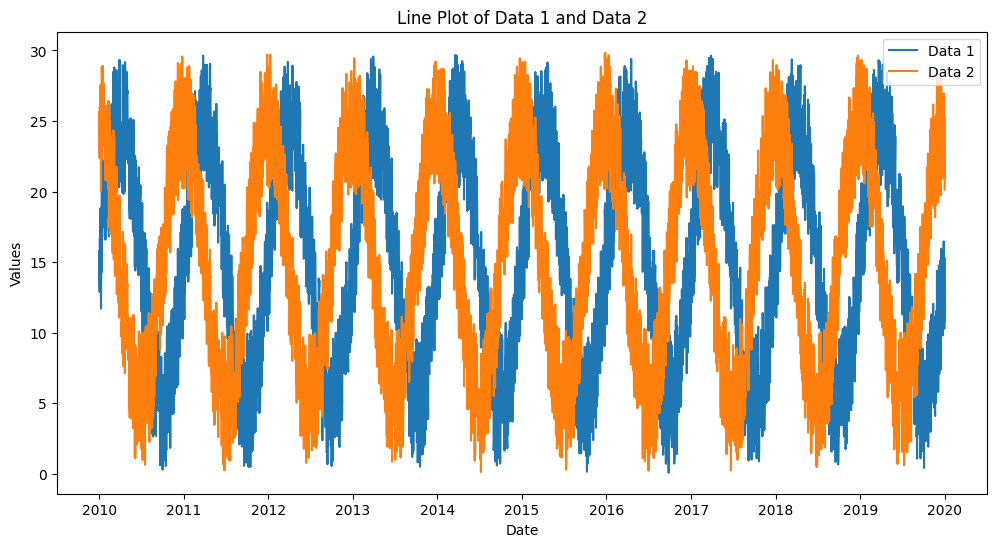

In [22]:
# Make a line plot with both the data1 and data2 columns
plt.figure(figsize=(12, 6))
plt.plot(date_df['date'], date_df['data1'], label='Data 1')
plt.plot(date_df['date'], date_df['data2'], label='Data 2')
plt.xlabel('Date')
plt.ylabel('Values')
plt.title('Line Plot of Data 1 and Data 2')
plt.legend()
plt.show()

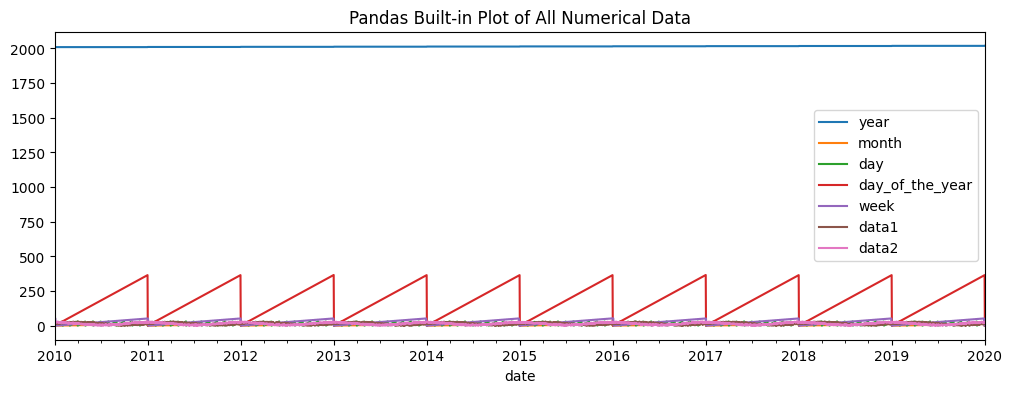

In [27]:
# Now use the builtin pandas plot routine to plot all the numerical data
# in the dataframe
date_df.plot(x='date', figsize=(12, 4))
plt.title('Pandas Built-in Plot of All Numerical Data')
plt.show()

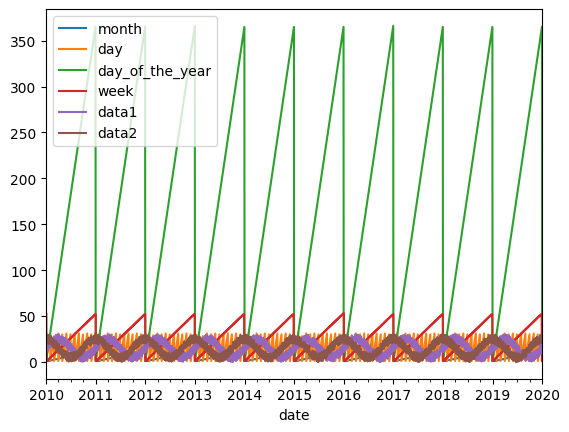

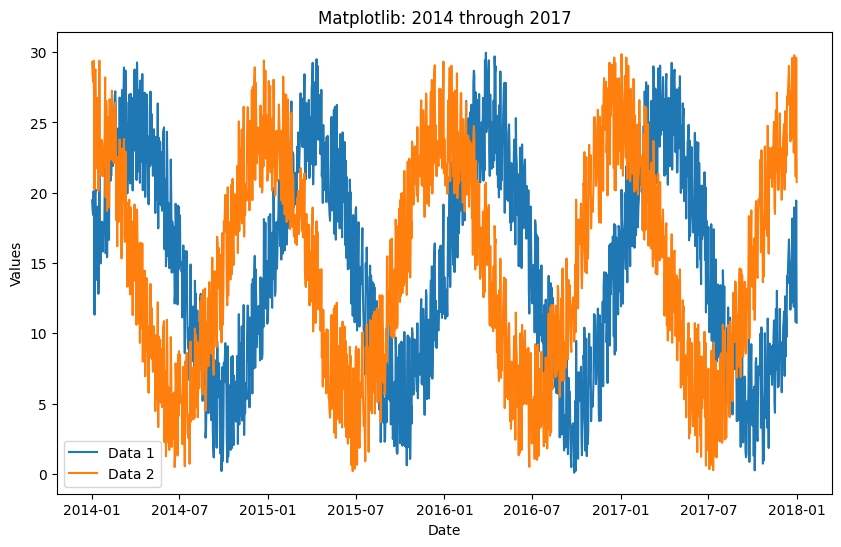

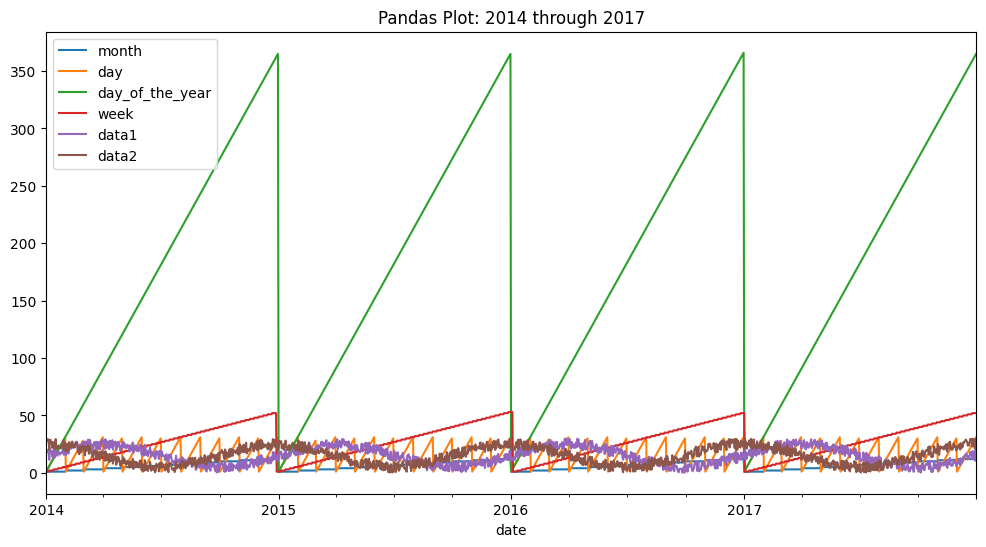

In [29]:
# drop the  year column from the plot because of the scale it was hard
# to see in the data in the other columns
date_df.drop('year', axis=1).plot(x='date')
plt.show()

# Filter only 2014 through 2017
filtered_df = date_df[(date_df['year'] >= 2014) & (date_df['year'] <= 2017)]

# Use matplotlib
plt.figure(figsize=(10, 6))
plt.plot(filtered_df['date'], filtered_df['data1'], label='Data 1')
plt.plot(filtered_df['date'], filtered_df['data2'], label='Data 2')
plt.title('Matplotlib: 2014 through 2017')
plt.xlabel('Date')
plt.ylabel('Values')
plt.legend()
plt.show()

# Use the dataframe .plot() method
filtered_df.drop('year', axis=1).plot(x='date', figsize=(12, 6))
plt.title('Pandas Plot: 2014 through 2017')
plt.show()

## Part 2 - Accident Data

Now we will start to look at the accident data in the Excel
Spreadsheet

In [26]:
# read the data into a pandas data frame called accidents_df

accidents_df = pd.read_excel('accidents.xlsx')
accidents_df.head()



,Date,Injury Location,Gender,Age Group,Incident Type,Days Lost,Plant,Report Type,Shift,Department,Incident Cost
0,2020-01-01,Multiple,Male,25-34,Burn,0.0,Iowa,Near Miss,Afternoon,Painting,0
1,2020-01-03,NaN,Male,35-49,Vehicle,0.5,Alabama,Lost Time,Day,Fabrication,3367
2,2020-01-03,Eye,Male,18-24,Cut,0.0,Georgia,Near Miss,Day,Administration,0
3,2020-01-04,Legs,Female,50+,Falling object,0.0,Iowa,Near Miss,Day,Painting,0
4,2020-01-07,Legs,Male,25-34,Lifting,0.0,Ohio,Near Miss,Day,Painting,0


In [32]:
# Change the data type of the Date column to datetime and make it the index

accidents_df['Date'] = pd.to_datetime(accidents_df['Date'])
accidents_df.set_index('Date', inplace=True)
accidents_df.head()


,Injury Location,Gender,Age Group,Incident Type,Days Lost,Plant,Report Type,Shift,Department,Incident Cost
Date,,,,,,,,,,
2020-01-01,Multiple,Male,25-34,Burn,0.0,Iowa,Near Miss,Afternoon,Painting,0
2020-01-03,NaN,Male,35-49,Vehicle,0.5,Alabama,Lost Time,Day,Fabrication,3367
2020-01-03,Eye,Male,18-24,Cut,0.0,Georgia,Near Miss,Day,Administration,0
2020-01-04,Legs,Female,50+,Falling object,0.0,Iowa,Near Miss,Day,Painting,0
2020-01-07,Legs,Male,25-34,Lifting,0.0,Ohio,Near Miss,Day,Painting,0


### Explore the data

How many unique values are there for:
- Location
- Age Group
- Plant
- Report Type
- Shift
- Department


Pick any three and print the information

In [34]:
# HINT: Use the .nunique() method and pass a column name
accidents_df['Injury Location'].nunique()
accidents_df['Age Group'].nunique()
accidents_df['Plant'].nunique()
accidents_df['Report Type'].nunique()
accidents_df['Shift'].nunique()
accidents_df['Department'].nunique()



9

In [35]:
# Call the nunique() method without any arguments
nunique_values = accidents_df.nunique()
print(nunique_values)


Injury Location     11
Gender               2
Age Group            4
Incident Type        9
Days Lost           11
Plant                9
Report Type          4
Shift                3
Department           9
Incident Cost      357
dtype: int64


### Answer the following questions

* Which Gender has the most accidents?
 * how many?
* Which plant has the most accidents?
 * how many?

Make bar charts (3 different ones) that show:

   * accident count per age group
   * accident count per plant
   * accident count per shift


In [36]:
#Accidents (Gender)
accidents_df['Gender'].value_counts()

,count
Gender,
Male,458
Female,56


In [37]:
# Accidents (Plant)
accidents_df['Plant'].value_counts()

,count
Plant,
Montana,64
Illinois,61
Florida,59
Georgia,58
Ohio,56
Texas,56
California,54
Alabama,54
Iowa,52


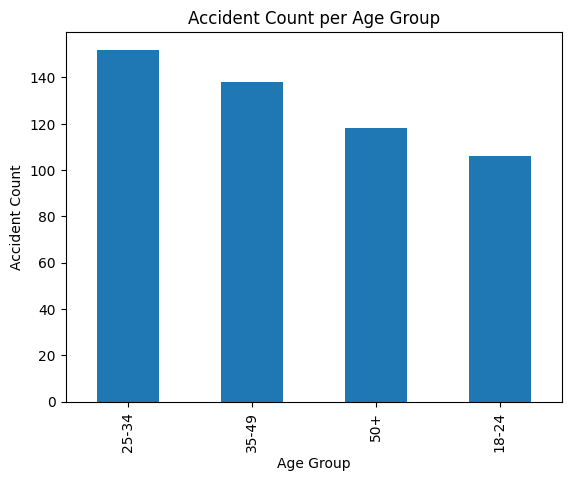

In [38]:
# Accident per age group chart
accidents_df['Age Group'].value_counts().plot(kind='bar')
plt.title('Accident Count per Age Group')
plt.xlabel('Age Group')
plt.ylabel('Accident Count')
plt.show()



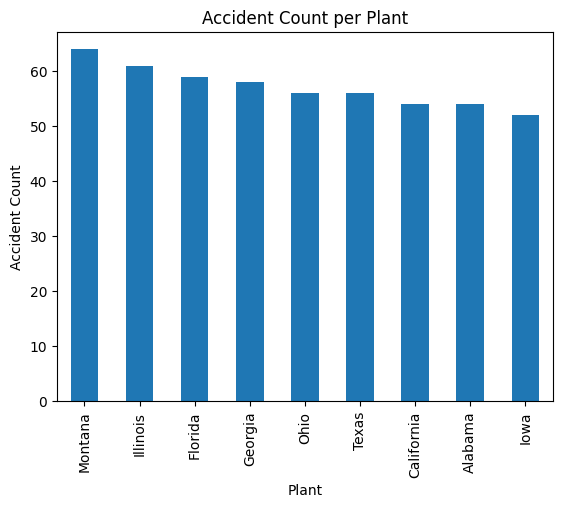

In [39]:
# Accident per plant chart
accidents_df['Plant'].value_counts().plot(kind='bar')
plt.title('Accident Count per Plant')
plt.xlabel('Plant')
plt.ylabel('Accident Count')
plt.show()

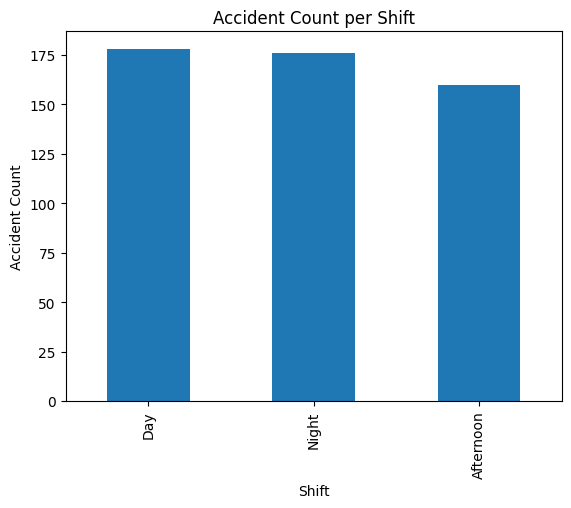

In [40]:
# Accident per shift chart
accidents_df['Shift'].value_counts().plot(kind='bar')
plt.title('Accident Count per Shift')
plt.xlabel('Shift')
plt.ylabel('Accident Count')
plt.show()

### Now some more involved analysis and graphs:

* Print a table of the days lost for each plant
 * total for each plant with
    * sub-categories of Gender
 * Make a bar chart

* Make a pie chart of the number of different types of accidents
* Make a pie chart of the accidents per age group
* Make a bar chart of the cost of the different types of accidents

In [42]:
#Table of the days lost for each plant
accidents_df.groupby('Plant')['Days Lost'].sum()


#Total for each plant with Gender
accidents_df.groupby(['Plant', 'Gender'])['Days Lost'].sum()


Plant       Gender
Alabama     Female    10.5
            Male      26.0
California  Female     8.5
            Male      30.0
Florida     Female     0.0
            Male      43.5
Georgia     Female     1.0
            Male      37.5
Illinois    Female     0.0
            Male      31.0
Iowa        Female     9.0
            Male      37.0
Montana     Female     5.0
            Male      38.5
Ohio        Female    14.5
            Male      30.0
Texas       Female     8.0
            Male      48.5
Name: Days Lost, dtype: float64

Text(0, 0.5, 'Days Lost')

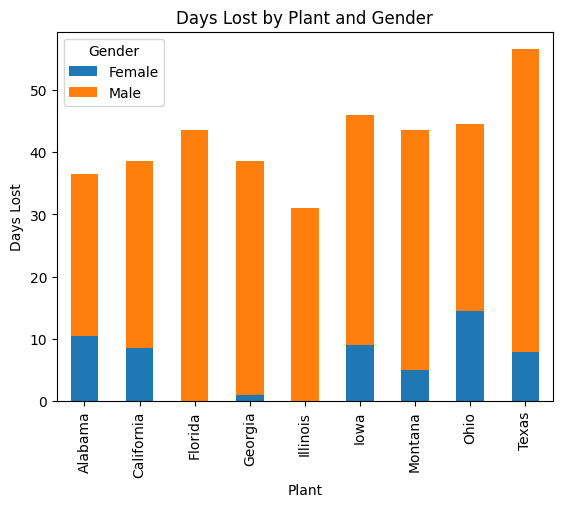

In [43]:
# bar-charts with either side-by-side or stacked bars for the genders
accidents_df.groupby(['Plant', 'Gender'])['Days Lost'].sum().unstack().plot(kind='bar', stacked=True)
plt.title('Days Lost by Plant and Gender')
plt.xlabel('Plant')
plt.ylabel('Days Lost')


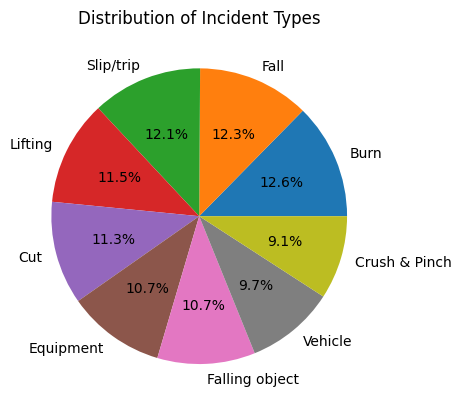

In [44]:
# Chart of different types of incidents
accidents_df['Incident Type'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Distribution of Incident Types')
plt.ylabel('')
plt.show()


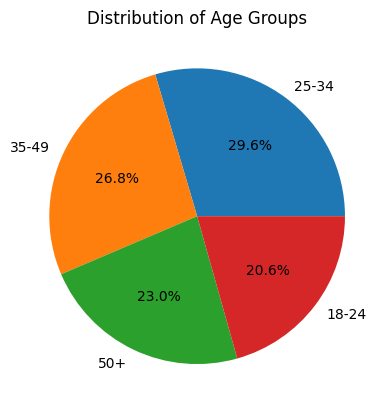

In [45]:
# Chart for age group
accidents_df['Age Group'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Distribution of Age Groups')
plt.ylabel('')
plt.show()


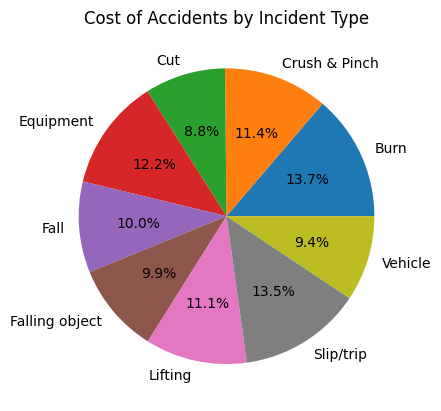

In [47]:
# Costs of accidents by incident type
accidents_df.groupby('Incident Type')['Incident Cost'].sum().plot(kind='pie', autopct='%1.1f%%')
plt.title('Cost of Accidents by Incident Type')
plt.ylabel('')
plt.show()


### Analyze by days of the week

Make a bar chart showing
* which day of the week has the most accidents
* accident costs for each day of the week

Do the same for the months.

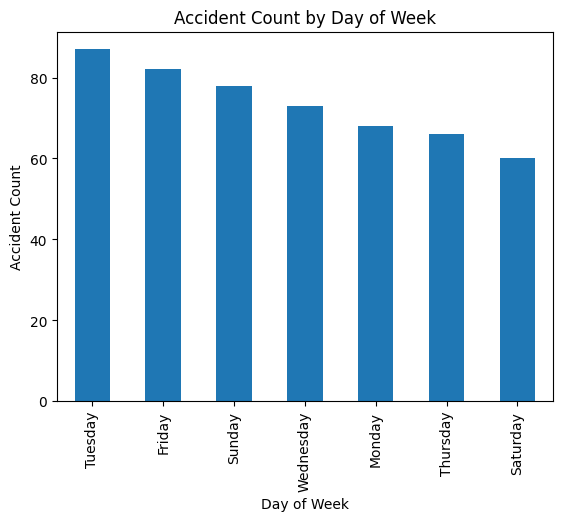

In [49]:
# Day of week accidents
accidents_df.index.day_name().value_counts().plot(kind='bar')
plt.title('Accident Count by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Accident Count')
plt.show()

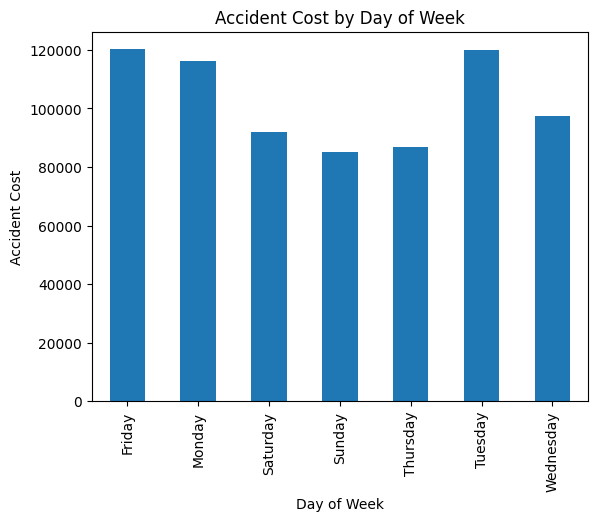

In [50]:
# Accident cost day of week
accidents_df.groupby(accidents_df.index.day_name())['Incident Cost'].sum().plot(kind='bar')
plt.title('Accident Cost by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Accident Cost')
plt.show()


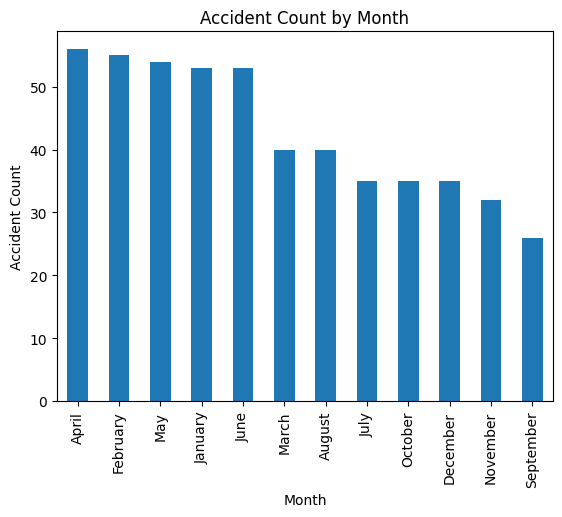

In [51]:
# Month accidents
accidents_df.index.month_name().value_counts().plot(kind='bar')
plt.title('Accident Count by Month')
plt.xlabel('Month')
plt.ylabel('Accident Count')
plt.show()


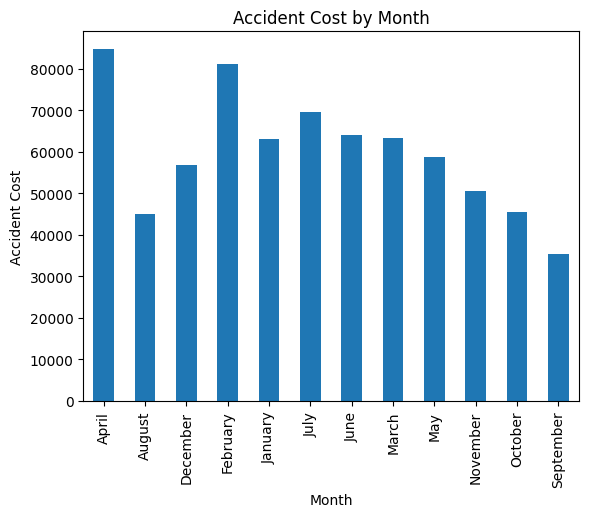

In [52]:
# Accident costs for each month
accidents_df.groupby(accidents_df.index.month_name())['Incident Cost'].sum().plot(kind='bar')
plt.title('Accident Cost by Month')
plt.xlabel('Month')
plt.ylabel('Accident Cost')
plt.show()
